# Flowbase Customer Support Analysis

## About this project

This notebook analyses **customer support data** for **Flowbase**, a made-up B2B SaaS company that sells project-management and workflow software to businesses.

The data covers two years, from **1 July 2024 to 30 June 2026**. It is **synthetic**: a Python script ([`src/generate_dataset.py`](../src/generate_dataset.py)) generated it, so no real customers are involved. The script still builds in the kinds of patterns you would find in a real helpdesk export, with realistic noise on top.

## Goals

1. **Support performance:** How fast does the team respond and resolve tickets? How often do we miss the SLA?
2. **Customer satisfaction (CSAT):** What leads to high or low satisfaction scores?
3. **Customer emotion:** The tone of each message (angry, frustrated, anxious, confused, neutral, positive) is not labelled. It is only in the text, so we need NLP to find it.
4. **Churn:** Which customers cancel, and can we predict it from their support history?
5. **Business events:** Can we spot a **platform outage (2025-03-11)** and a **price increase (2025-09-01)** in the data?

## The data

| File | Rows | One row per… |
|---|---|---|
| `support_tickets.csv` | ~17,400 | support ticket (main dataset) |
| `customers.csv` | 3,200 | customer account |
| `agents.csv` | 35 | support agent |

The tables join on `customer_id` and `agent_id`. The full column list is in [`data/DATA_DICTIONARY.md`](../data/DATA_DICTIONARY.md).

## Key terms

- **Ticket:** a request for help from a customer, such as "I was charged twice".
- **Channel:** how the customer got in touch: Email, Chat, Web Form, Phone or In-App Messenger.
- **First response time:** how long the customer waited for the first reply from an agent.
- **SLA (Service Level Agreement):** the promised maximum wait for a first reply. A ticket is *breached* when the reply came too late.
- **CSAT:** a 1–5 satisfaction score given after the ticket is resolved. About 60% of customers skip the survey, so many scores are empty.
- **MRR (Monthly Recurring Revenue):** how much a customer pays per month.
- **Churn:** a customer cancelling and leaving the product.

## Contents

1. Load the data and first look
2. Data cleaning
3. Exploratory data analysis (8 questions)
4. Churn prediction
5. Questions and answers (summary of the project)

## Tools

Python, pandas, numpy, matplotlib, seaborn and scikit-learn.

## How to run

Open this notebook in Jupyter or VS Code and choose **Run All**. The data is read from the `data/` folder next to this notebook's folder, so keep the project folders as they are.

> ⚠️ **Data leakage:** `churned`, `customer_churned`, `churn_date`, `churned_within_90d`, `churn_reason` and `account_status` are the churn answers. Leave them out of the inputs when you build a churn prediction model.

## 1. Load the data and first look

First I import all the libraries, load the three tables and check their size, column types, duplicates and missing values.

In [100]:
import os
import re

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score, ConfusionMatrixDisplay

In [64]:
customers = pd.read_csv('../data/customers.csv',
                        parse_dates=['signup_date', 'churn_date', 'last_ticket_date'])
agents = pd.read_csv('../data/agents.csv', parse_dates=['hire_date'])
support_tickets = pd.read_csv('../data/support_tickets.csv',
                              parse_dates=['created_at', 'first_response_at', 'resolved_at', 'churn_date'])

In [65]:
customers.info()

<class 'pandas.DataFrame'>
RangeIndex: 3200 entries, 0 to 3199
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   customer_id       3200 non-null   str           
 1   company_name      3200 non-null   str           
 2   plan_tier         3200 non-null   str           
 3   billing_cycle     3200 non-null   str           
 4   seats             3200 non-null   int64         
 5   mrr_usd           3200 non-null   float64       
 6   industry          3200 non-null   str           
 7   region            3200 non-null   str           
 8   country           3200 non-null   str           
 9   signup_date       3200 non-null   datetime64[us]
 10  primary_contact   3200 non-null   str           
 11  account_status    3200 non-null   str           
 12  churned           3200 non-null   bool          
 13  churn_date        833 non-null    datetime64[us]
 14  churn_reason      833 non-null    s

In [66]:
customers.sample(5)

,customer_id,company_name,plan_tier,billing_cycle,seats,mrr_usd,industry,region,country,signup_date,primary_contact,account_status,churned,churn_date,churn_reason,total_tickets,avg_csat,last_ticket_date
2941,CUST-12942,Lumenhub Logistics,Business,Monthly,175,8575.00,Marketing Agency,EMEA,United Kingdom,2022-04-22,Jessica Robinson,Active,False,NaT,NaN,8,5.0,2026-03-18 11:37:33
2460,CUST-12461,Harborbridge Solutions,Business,Annual,59,2399.53,Healthcare,EMEA,United Arab Emirates,2021-09-20,Beatriz Pereira,Active,False,NaT,NaN,8,3.8,2026-05-29 17:15:16
1789,CUST-11790,Apexgrid Inc,Business,Annual,112,4555.04,Logistics,APAC,India,2025-09-05,Lin Garcia,Churned,True,2026-03-19,Unknown / silent churn,1,NaN,2026-03-11 14:16:49
2949,CUST-12950,Brightstack Digital,Starter,Monthly,3,36.00,Software,North America,United States,2026-04-08,Ahmed Nilsson,Churned,True,2026-06-23,Unknown / silent churn,0,NaN,NaT
2752,CUST-12753,Peakscale Systems,Business,Annual,145,5897.15,Marketing Agency,EMEA,United Arab Emirates,2023-03-11,Isabela Smith,Churned,True,2024-08-25,Unknown / silent churn,3,5.0,2024-08-21 11:11:58


In [67]:
customers["customer_id"].nunique()


3200

In [68]:
customers["churned"].value_counts()

churned
False    2367
True      833
Name: count, dtype: int64

In [69]:
customers["churned_flag"] = customers["churned"].map({True: 1, False: 0})

customers[["customer_id", "churned", "churned_flag"]].head()


,customer_id,churned,churned_flag
0,CUST-10001,False,0
1,CUST-10002,False,0
2,CUST-10003,True,1
3,CUST-10004,True,1
4,CUST-10005,False,0


In [70]:
customers["churn_reason"].value_counts()

churn_reason
Unknown / silent churn     513
Too expensive               96
Company closing             53
Switching to competitor     47
Not using enough            45
Poor support experience     44
Missing features            35
Name: count, dtype: int64

In [71]:
agents.info()

<class 'pandas.DataFrame'>
RangeIndex: 35 entries, 0 to 34
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   agent_id    35 non-null     str           
 1   agent_name  35 non-null     str           
 2   team        35 non-null     str           
 3   hire_date   35 non-null     datetime64[us]
 4   shift       35 non-null     str           
dtypes: datetime64[us](1), str(4)
memory usage: 1.5 KB


In [72]:
agents.sample(5)


,agent_id,agent_name,team,hire_date,shift
24,AG-125,Priya W.,Tier 2 Technical,2020-08-08,AMER
10,AG-111,Mateus C.,Tier 1 Support,2019-05-08,AMER
18,AG-119,Matthew T.,Tier 2 Technical,2021-07-22,EMEA
34,AG-135,Andrew R.,Customer Success / Retention,2021-08-29,AMER
32,AG-133,Mariana C.,Customer Success / Retention,2022-09-16,EMEA


In [73]:
support_tickets.info()

<class 'pandas.DataFrame'>
RangeIndex: 17381 entries, 0 to 17380
Data columns (total 40 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   ticket_id                 17381 non-null  str           
 1   created_at                17381 non-null  datetime64[us]
 2   first_response_at         17381 non-null  datetime64[us]
 3   resolved_at               17363 non-null  datetime64[us]
 4   status                    17381 non-null  str           
 5   channel                   17381 non-null  str           
 6   category                  17381 non-null  str           
 7   subcategory               17381 non-null  str           
 8   priority                  17381 non-null  str           
 9   subject                   17381 non-null  str           
 10  customer_message          17381 non-null  str           
 11  agent_first_response      17381 non-null  str           
 12  agent_id                  173

In [74]:
support_tickets.sample(5)

,ticket_id,created_at,first_response_at,resolved_at,status,channel,category,subcategory,priority,subject,...,seats,mrr_usd,industry,region,country,account_age_days,days_since_prev_ticket,customer_churned,churn_date,churned_within_90d
4436,TKT-204437,2025-01-21 08:46:36,2025-01-21 08:47:33,2025-01-21 22:58:25,Closed,Chat,Billing,Tax / VAT details,Medium,Chat conversation with Jessica,...,8,232.00,Software,North America,United States,1578,63.0,False,NaT,False
14662,TKT-214663,2026-03-12 10:32:18,2026-03-12 13:16:35,2026-03-13 01:42:39,Closed,Web Form,Cancellation Request,Company closing,Medium,Please cancel,...,1,12.00,Healthcare,APAC,Australia,196,NaN,True,2026-04-01,True
11363,TKT-211364,2025-10-29 07:53:47,2025-10-29 09:40:50,2025-11-02 13:38:48,Closed,Email,Performance,Possible outage,Urgent,Performance issues,...,33,1342.11,Financial Services,North America,United States,150,57.0,False,NaT,False
421,TKT-200422,2024-07-22 10:08:31,2024-07-22 12:43:35,2024-07-23 15:18:53,Closed,Email,Technical Issue,Error message,Low,Not working,...,40,1960.00,Financial Services,North America,United States,435,NaN,True,2025-07-26,False
1258,TKT-201259,2024-08-28 17:28:33,2024-08-28 18:01:32,2024-08-29 04:54:40,Closed,Email,Integration,Sync stopped,Urgent,Webhook problem,...,52,2114.84,Professional Services,EMEA,United Kingdom,1252,NaN,False,NaT,False


In [75]:
support_tickets.duplicated().sum()

np.int64(0)

In [76]:
customers.duplicated().sum()

np.int64(0)

In [77]:
support_tickets["churned_within_90d_flag"] = support_tickets["churned_within_90d"].map({True: 1, False: 0})

support_tickets[["customer_id", "churned_within_90d", "churned_within_90d_flag"]].head()

,customer_id,churned_within_90d,churned_within_90d_flag
0,CUST-11587,False,0
1,CUST-10526,False,0
2,CUST-12677,False,0
3,CUST-12093,False,0
4,CUST-11581,False,0


In [78]:
support_tickets["category"].value_counts()

category
Technical Issue         3041
Billing                 2648
How-to / Onboarding     2504
Account Access          2073
Integration             1991
Bug Report              1364
Performance             1040
Feature Request         1035
Cancellation Request     913
Data & Export            772
Name: count, dtype: int64

In [79]:
for name, df in [("tickets", support_tickets), ("customers", customers), ("agents", agents)]:
	missing = df.isna().sum()
	missing = missing[missing > 0]
	print(f"\n--- {name.upper()} ---")
	if missing.empty:
		print("No missing values.")
	else:
		print(missing.to_string())
	print(f"Total missing cells: {df.isna().sum().sum()}")


--- TICKETS ---
resolved_at                    18
resolution_time_hrs            18
csat_score                  10507
csat_comment                14951
retention_offer_accepted    16468
days_since_prev_ticket       2925
churn_date                  13723
Total missing cells: 58610

--- CUSTOMERS ---
churn_date          2367
churn_reason        2367
avg_csat             933
last_ticket_date     275
Total missing cells: 5942

--- AGENTS ---
No missing values.
Total missing cells: 0


### What I learned from the first look

- The data has **3,200 customers**, **35 agents** and **17,381 tickets**.
- **833 customers (26.0%) churned.** Most of them (513) left without giving a reason ("Unknown / silent churn"). The most common reason given is "Too expensive" (96).
- There are **no duplicate rows** in the tickets or customers tables.
- The most common ticket categories are Technical Issue (3,041), Billing (2,648) and How-to / Onboarding (2,504).
- Some columns have missing values, for example `csat_score` and `churn_date`. Section 2 checks *why* they are missing.

## 2. Data cleaning

Goal: make the data trustworthy before any analysis. The steps:

1. **Missing values:** find out *why* each value is missing before deciding anything
2. **Survey check:** is skipping the CSAT survey random?
3. **Text consistency:** extra spaces, spelling variants, hidden missing values
4. **Logic checks:** values that are present but impossible
5. **Fixes:** apply the decisions from steps 1–4
6. **Outliers:** decide what to do with extreme values
7. **Helper columns:** flags and date parts for the analysis
8. **Summary and save**

(Duplicates were already checked in section 1.)

**Rule I follow:** when a ticket is real but one of its values is wrong, I remove the wrong *value* (set it to missing) instead of deleting the whole ticket. Deleting the row would make ticket volumes too low.

In [80]:
# Remember the starting size, to report what cleaning changed
raw_rows = {'tickets': len(support_tickets), 'customers': len(customers), 'agents': len(agents)}
raw_cols = set(support_tickets.columns)

t = support_tickets   # short name for the same table (not a copy)
c = customers
raw_rows

{'tickets': 17381, 'customers': 3200, 'agents': 35}

### 2.1 Missing values: why are they missing?

In this dataset most missing values are not errors: they *mean* something (a ticket is still open, a customer skipped the survey). Each check below tests one explanation.

In [81]:
# 1. resolved_at / resolution_time_hrs: are these tickets still open?
print('Status of tickets without resolved_at:')
print(t.loc[t['resolved_at'].isna(), 'status'].value_counts().to_string())
print('Both columns missing on the same rows:',
      (t['resolved_at'].isna() == t['resolution_time_hrs'].isna()).all())
print()

# 2. retention_offer_accepted: only filled for cancellation tickets?
print('Categories where retention_offer_accepted is filled:')
print(t.loc[t['retention_offer_accepted'].notna(), 'category'].value_counts().to_string())
print()

# 3. days_since_prev_ticket: missing on the customer's first ticket?
first_ticket = t['created_at'] == t.groupby('customer_id')['created_at'].transform('min')
print('Missing days_since_prev_ticket <=> first ticket:',
      (t['days_since_prev_ticket'].isna() == first_ticket).all())
print('Customers with at least one ticket:', t['customer_id'].nunique())

Status of tickets without resolved_at:
status
Pending    18
Both columns missing on the same rows: True

Categories where retention_offer_accepted is filled:
category
Cancellation Request    913

Missing days_since_prev_ticket <=> first ticket: True
Customers with at least one ticket: 2925


In [82]:
# 4. churn_date in tickets: missing only when the customer did not churn?
print('Tickets: churn_date missing <=> not churned:',
      (t['churn_date'].isna() == ~t['customer_churned']).all())

# 5. churn_date / churn_reason in customers
print('Customers: churn_date missing <=> not churned:',
      (c['churn_date'].isna() == ~c['churned']).all())
print('Customers: churn_reason missing <=> not churned:',
      (c['churn_reason'].isna() == ~c['churned']).all())

# 6. last_ticket_date: missing for customers who never opened a ticket?
print('last_ticket_date missing <=> total_tickets == 0:',
      (c['last_ticket_date'].isna() == (c['total_tickets'] == 0)).all())

# 7. avg_csat: no tickets, or tickets but never answered a survey?
answered_ids = t.loc[t['csat_score'].notna(), 'customer_id'].unique()
no_tickets = c['total_tickets'] == 0
never_answered = ~no_tickets & ~c['customer_id'].isin(answered_ids)
print(f"avg_csat missing: {c['avg_csat'].isna().sum()} "
      f"= no tickets ({no_tickets.sum()}) + tickets but no survey answer ({never_answered.sum()})")

Tickets: churn_date missing <=> not churned: True
Customers: churn_date missing <=> not churned: True
Customers: churn_reason missing <=> not churned: True
last_ticket_date missing <=> total_tickets == 0: True
avg_csat missing: 933 = no tickets (275) + tickets but no survey answer (658)


#### My missing values explained

- **18 unresolved tickets** all have status *Pending*. They are open tickets, not broken data.
- **913 retention offers** match the 913 Cancellation Requests exactly.
- Missing `days_since_prev_ticket` is always the customer's **first ticket** (2,925 rows). This matches the 3,200 − 275 = 2,925 customers who have at least one ticket.
- Churn dates and reasons are missing only for customers who **did not churn**.
- Missing `avg_csat`: 275 customers with no tickets + 658 who never answered a survey = 933, so every case is explained.

Because every gap has a clear reason, **I don't fill or drop anything here**. Filling them would hide real information, such as "this customer never answers surveys".

### 2.2 Survey check

In [84]:
answered = t['csat_score'].notna().rename('csat_answered')
print(f'CSAT response rate: {answered.mean() * 100:.1f}%')

(t.groupby(answered)[['sla_breached', 'escalated', 'reopened', 'churned_within_90d']]
   .mean().mul(100).round(1)
   .rename(columns=lambda col: col + '_%'))

CSAT response rate: 39.5%


,sla_breached_%,escalated_%,reopened_%,churned_within_90d_%
csat_answered,,,,
False,11.3,10.0,8.2,8.9
True,11.0,9.6,8.0,8.9


**Is skipping the survey random?**

39.5% of tickets have a CSAT score. Tickets with and without a score have almost the same rates of SLA breach, escalation, reopening and churn (all differences under 0.5 percentage points). Customers who skipped the survey did not have a worse experience, so CSAT averages are a fair picture of all customers.

*Limitation:* this only compares measurable signals. The opinion of customers who didn't answer remains unknown.

### 2.3 Text consistency

In [85]:
def text_columns(frame):
    """Columns that hold text (pandas 3 'str' or older 'object')."""
    return [col for col in frame.columns
            if pd.api.types.is_string_dtype(frame[col]) or frame[col].dtype == 'object']


tables = {'tickets': support_tickets, 'customers': customers, 'agents': agents}

# Remove spaces at the start and end of every text value
for frame in tables.values():
    for col in text_columns(frame):
        frame[col] = frame[col].str.strip()

# Hidden missing values and case variants
placeholders = ['', 'n/a', 'na', 'none', 'null', 'nan', 'unknown', '-', '?']
for name, frame in tables.items():
    for col in text_columns(frame):
        hidden = frame[col].str.lower().isin(placeholders).sum()
        if hidden:
            print(f'{name}.{col}: {hidden} placeholder values')
        if frame[col].str.lower().nunique() < frame[col].nunique():
            print(f'{name}.{col}: same value written with different upper/lower case')
print('Text check done.')

tickets.customer_message: same value written with different upper/lower case
Text check done.


In [86]:
# Look at every short list of categories to spot spelling variants by eye
for name, frame in tables.items():
    for col in text_columns(frame):
        n = frame[col].nunique()
        if n <= 15:
            print(f'{name}.{col} ({n}): {sorted(frame[col].dropna().unique())}')

tickets.status (3): ['Closed', 'Pending', 'Solved']
tickets.channel (5): ['Chat', 'Email', 'In-App Messenger', 'Phone', 'Web Form']
tickets.category (10): ['Account Access', 'Billing', 'Bug Report', 'Cancellation Request', 'Data & Export', 'Feature Request', 'How-to / Onboarding', 'Integration', 'Performance', 'Technical Issue']
tickets.priority (4): ['High', 'Low', 'Medium', 'Urgent']
tickets.agent_team (4): ['Billing Ops', 'Customer Success / Retention', 'Tier 1 Support', 'Tier 2 Technical']
tickets.retention_offer_accepted (2): ['No', 'Yes']
tickets.plan_tier (4): ['Business', 'Enterprise', 'Professional', 'Starter']
tickets.billing_cycle (2): ['Annual', 'Monthly']
tickets.industry (12): ['E-commerce', 'Education', 'Financial Services', 'Healthcare', 'Logistics', 'Manufacturing', 'Marketing Agency', 'Media & Entertainment', 'Non-profit', 'Professional Services', 'Real Estate', 'Software']
tickets.region (4): ['APAC', 'EMEA', 'LATAM', 'North America']
customers.plan_tier (4): ['Busin

**Result:** no hidden missing values (like "n/a" or "unknown") and no spelling variants in the category columns. The only upper/lower case variants are in `customer_message`, which is free text, so that is expected.

### 2.4 Logic checks

In [87]:
customer_info = c.set_index('customer_id')
signup = t['customer_id'].map(customer_info['signup_date'])
churned_in_customers = t['customer_id'].map(customer_info['churned'])

# Recalculate the duration columns from the timestamps
frt_calc = (t['first_response_at'] - t['created_at']).dt.total_seconds() / 60
res_calc = (t['resolved_at'] - t['created_at']).dt.total_seconds() / 3600

checks = {
    # Order of timestamps
    'first response before created':       t['first_response_at'] < t['created_at'],
    'resolved before created':             t['resolved_at'] < t['created_at'],
    'resolved before first response':      t['resolved_at'] < t['first_response_at'],
    'created outside study period':        ~t['created_at'].between('2024-07-01', '2026-07-01'),
    'ticket before customer signup':       t['created_at'].dt.normalize() < signup,
    # Durations
    'negative first_response_time_min':    t['first_response_time_min'] < 0,
    'negative resolution_time_hrs':        t['resolution_time_hrs'] < 0,
    'first_response_time_min != timestamps': (frt_calc - t['first_response_time_min']).abs() > 1,
    'resolution_time_hrs != timestamps':   (res_calc - t['resolution_time_hrs']).abs() > 0.1,
    'sla_breached != response time':       (t['first_response_time_min'] > t['sla_target_min']) != t['sla_breached'],
    # Scores and numbers
    'csat outside 1-5':                    t['csat_score'].notna() & ~t['csat_score'].between(1, 5),
    'csat not a whole number':             t['csat_score'].notna() & (t['csat_score'] % 1 != 0),
    'seats below 1':                       t['seats'] < 1,
    'negative mrr_usd':                    t['mrr_usd'] < 0,
    'negative account_age_days':           t['account_age_days'] < 0,
    # Links between tables
    'customer_id not in customers':        ~t['customer_id'].isin(c['customer_id']),
    'agent_id not in agents':              ~t['agent_id'].isin(agents['agent_id']),
    'customer_churned != customers table': t['customer_churned'] != churned_in_customers,
    'ticket after churn_date':             t['churn_date'].notna() & (t['created_at'].dt.normalize() > t['churn_date']),
}

check_table = pd.DataFrame({'rows': {name: int(mask.sum()) for name, mask in checks.items()}})
check_table['pct'] = (check_table['rows'] / len(t) * 100).round(2)
check_table

,rows,pct
first response before created,0,0.0
resolved before created,0,0.0
resolved before first response,0,0.0
created outside study period,0,0.0
ticket before customer signup,0,0.0
negative first_response_time_min,0,0.0
negative resolution_time_hrs,0,0.0
first_response_time_min != timestamps,0,0.0
resolution_time_hrs != timestamps,0,0.0
sla_breached != response time,0,0.0


In [88]:
# Look at the rows behind any check that is not 0. Change the name to inspect another one.
check_name = 'resolved before first response'
t.loc[checks[check_name],
      ['ticket_id', 'created_at', 'first_response_at', 'resolved_at',
       'first_response_time_min', 'resolution_time_hrs', 'sla_target_min', 'sla_breached', 'csat_score']].head(10)

,ticket_id,created_at,first_response_at,resolved_at,first_response_time_min,resolution_time_hrs,sla_target_min,sla_breached,csat_score


In [89]:
# Checks on the customers and agents tables
print('account_status vs churned:')
print(pd.crosstab(c['account_status'], c['churned']))
print()

actual_tickets = t.groupby('customer_id').size().reindex(c['customer_id'], fill_value=0).values
print('total_tickets different from tickets in the data:', (c['total_tickets'] != actual_tickets).sum())

hire = t['agent_id'].map(agents.set_index('agent_id')['hire_date'])
print('Tickets handled before the agent was hired:', (t['created_at'] < hire).sum())

team_in_agents = t['agent_id'].map(agents.set_index('agent_id')['team'])
print('agent_team different from agents table:', (t['agent_team'] != team_in_agents).sum())

account_status vs churned:
churned         False  True 
account_status              
Active           2367      0
Churned             0    833

total_tickets different from tickets in the data: 0
Tickets handled before the agent was hired: 0
agent_team different from agents table: 0


**Result:** every check returned **0 rows**, and the customers and agents tables also match the tickets. The data passes all logic checks.

I keep the checks anyway, because they would catch problems if the data is regenerated or updated. Real errors would be timestamps in the wrong order, negative durations, CSAT outside 1–5, or IDs that don't exist in the other table (handled in 2.5). Some checks would not always mean an error:

- *Resolved before first response* can be a ticket closed by automation or by the customer.
- *Ticket after churn_date* can be a former customer asking about a refund or their data.
- *total_tickets* may also count tickets from before July 2024, which are not in this export.
- *sla_breached* may use `>=` instead of `>`, so a ticket that took exactly the target time would show as a mismatch.

### 2.5 Fixing the problems

The checks found nothing, so this code changes nothing on this data. It still shows how each problem would be handled: wrong times and scores become missing (the ticket is kept), and tickets with unknown IDs are dropped.

In [97]:
bad_response_time = (checks['first response before created']
                     | checks['negative first_response_time_min'])
bad_resolution_time = (checks['resolved before created']
                       | checks['negative resolution_time_hrs'])

t['time_issue'] = bad_response_time | bad_resolution_time
t.loc[bad_response_time, 'first_response_time_min'] = np.nan
t.loc[bad_resolution_time, 'resolution_time_hrs'] = np.nan

t.loc[checks['csat outside 1-5'], 'csat_score'] = np.nan

orphans = checks['customer_id not in customers'] | checks['agent_id not in agents']
support_tickets = support_tickets.loc[~orphans].copy()
t = support_tickets

print('Times set to missing:', int(bad_response_time.sum() + bad_resolution_time.sum()))
print('CSAT scores removed: ', int(checks['csat outside 1-5'].sum()))
print('Tickets dropped:     ', int(orphans.sum()))
print(f'Tickets remaining:    {len(t):,}')

Times set to missing: 0
CSAT scores removed:  0
Tickets dropped:      0
Tickets remaining:    17,381


### 2.6 Outliers

In [90]:
numeric_cols = ['first_response_time_min', 'resolution_time_hrs', 'agent_replies',
                'customer_replies', 'seats', 'mrr_usd', 'account_age_days']
t[numeric_cols].describe(percentiles=[0.5, 0.9, 0.99]).round(1)

,first_response_time_min,resolution_time_hrs,agent_replies,customer_replies,seats,mrr_usd,account_age_days
count,17381.0,17363.0,17381.0,17381.0,17381.0,17381.0,17381.0
mean,179.1,31.2,2.6,2.7,233.0,11873.9,896.1
std,362.0,51.3,2.0,2.1,467.4,25024.8,568.5
min,0.3,0.4,1.0,1.0,1.0,10.0,0.0
50%,59.5,14.0,2.0,2.0,40.0,1372.0,870.0
90%,474.6,78.7,5.0,5.0,756.0,39863.8,1680.0
99%,1527.2,237.1,10.0,10.0,2190.0,116397.9,2037.2
max,13499.5,1156.2,33.0,33.0,2469.0,131990.1,2209.0


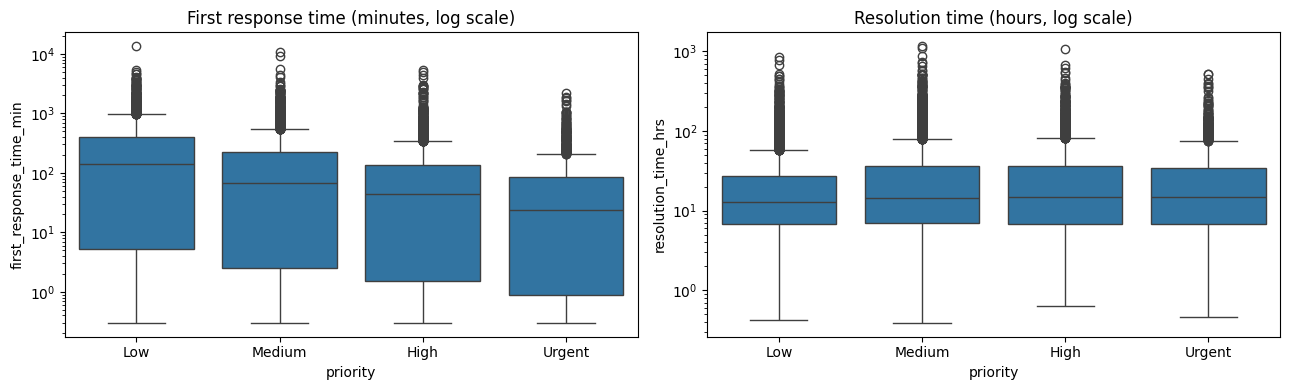

In [91]:
priority_order = [p for p in ['Low', 'Medium', 'High', 'Urgent', 'Critical']
                  if p in t['priority'].unique()]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=t, x='priority', y='first_response_time_min', order=priority_order, ax=axes[0])
sns.boxplot(data=t, x='priority', y='resolution_time_hrs', order=priority_order, ax=axes[1])
for ax in axes:
    ax.set_yscale('log')   # log scale, otherwise the long tickets squash everything else
axes[0].set_title('First response time (minutes, log scale)')
axes[1].set_title('Resolution time (hours, log scale)')
plt.tight_layout()
plt.show()

In [92]:
cutoff = t['resolution_time_hrs'].quantile(0.99)
t['long_resolution'] = t['resolution_time_hrs'] > cutoff
print(f'Slowest 1%: more than {cutoff:.0f} hours ({cutoff / 24:.1f} days), '
      f'{t["long_resolution"].sum()} tickets')

Slowest 1%: more than 237 hours (9.9 days), 174 tickets


**Decision:** long resolution times are real tickets (often bugs waiting for Engineering), so I keep them. For time metrics I use the **median** instead of the average, because a few very long tickets would pull the average up. The slowest 1% (174 tickets, over 237 hours) is flagged with `long_resolution`.

### 2.7 Helper columns for the analysis

In [94]:
# Status flags
t['is_open'] = t['resolved_at'].isna()
t['is_first_ticket'] = t['days_since_prev_ticket'].isna()
t['csat_answered'] = t['csat_score'].notna()

# 1 = score of 1 or 2, 0 = score of 3-5, missing = no answer.
# Taking the mean of this column gives the % of unhappy customers among those who answered.
t['low_csat'] = (t['csat_score'] <= 2).astype(float).where(t['csat_answered'])

# Date parts for trends and workload patterns
t['created_date'] = t['created_at'].dt.normalize()
t['created_month'] = t['created_at'].dt.to_period('M')
t['created_weekday'] = t['created_at'].dt.day_name()
t['created_hour'] = t['created_at'].dt.hour

# Business events from the project goals
t['after_price_increase'] = t['created_at'] >= '2025-09-01'

t[['is_open', 'is_first_ticket', 'csat_answered', 'low_csat',
   'created_month', 'created_weekday', 'created_hour']].head()

,is_open,is_first_ticket,csat_answered,low_csat,created_month,created_weekday,created_hour
0,False,True,True,0.0,2024-07,Monday,2
1,False,True,False,NaN,2024-07,Monday,4
2,False,True,False,NaN,2024-07,Monday,4
3,False,True,False,NaN,2024-07,Monday,4
4,False,True,True,0.0,2024-07,Monday,5


In [95]:
# Columns that contain the churn answer. Never use them as model inputs.
LEAKAGE_COLS = ['churned', 'customer_churned', 'churn_date', 'churned_within_90d',
                'churn_reason', 'account_status', 'churned_flag', 'churned_within_90d_flag']

### 2.8 Cleaning summary and save

In [ ]:
# Compare the tables before and after cleaning
for name, frame in [('tickets', support_tickets), ('customers', customers), ('agents', agents)]:
    print(f'{name}: {raw_rows[name]:,} rows before -> {len(frame):,} rows after')

print()
print('New columns added to tickets:')
print(sorted(set(support_tickets.columns) - raw_cols))

**Cleaning summary**

- **Missing values:** every gap has a clear reason: open tickets, skipped surveys, first tickets, non-churned customers. Nothing was filled, because filling would invent information. CSAT is always reported together with its response rate.
- **Duplicates:** no duplicate rows in the tickets or customers tables.
- **Text:** extra spaces removed from all text columns. No spelling variants or placeholder values found.
- **Logic checks:** all checks passed, so 0 times were set to missing, 0 CSAT scores removed and 0 tickets dropped. All **17,381 tickets** are kept.
- **Outliers:** long resolution times kept, because they are real. Medians are used for time metrics, and the slowest 1% is flagged with `long_resolution`.
- **Added:** status flags, date parts, a `low_csat` flag, 0/1 churn flags, and a list of leakage columns to keep out of models.

The clean tables are saved to `data/clean/`.

In [101]:
os.makedirs('../data/clean', exist_ok=True)
support_tickets.to_csv('../data/clean/support_tickets_clean.csv', index=False)
customers.to_csv('../data/clean/customers_clean.csv', index=False)
agents.to_csv('../data/clean/agents_clean.csv', index=False)
print('Saved to ../data/clean/')

Saved to ../data/clean/


## 3. Exploratory data analysis

Each question has the code, a chart or table, and a short note:
**What I see** (the result) and **Why it matters** (what the business could do with it).

### 3.1 What do customers contact us about?

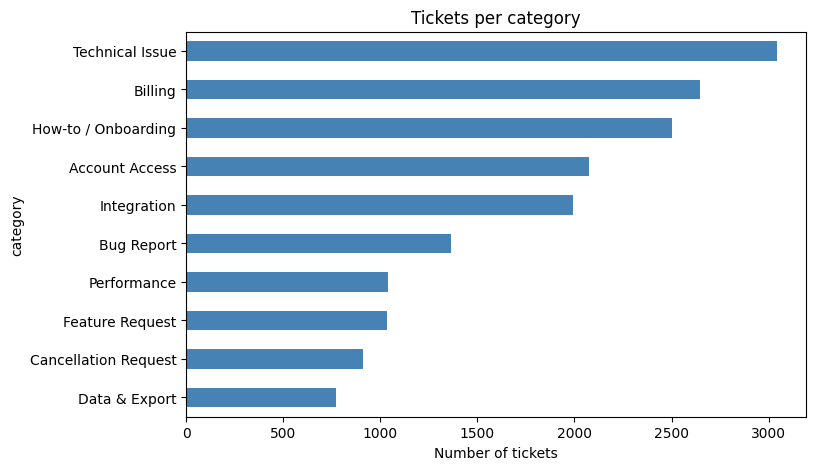

category
Technical Issue         17.5
Billing                 15.2
How-to / Onboarding     14.4
Account Access          11.9
Integration             11.5
Bug Report               7.8
Performance              6.0
Feature Request          6.0
Cancellation Request     5.3
Data & Export            4.4
Name: count, dtype: float64

In [105]:
# Number of tickets and % share per category
counts = t['category'].value_counts()
share_pct = (counts / counts.sum() * 100).round(1)

ax = counts.sort_values().plot(kind='barh', figsize=(8, 5), color='steelblue')
ax.set_title('Tickets per category')
ax.set_xlabel('Number of tickets')
plt.show()

share_pct

**What I see**: Technical Issue (17.5%), Billing (15.2%) and How-to / Onboarding (14.4%) are the three largest categories, together almost half of all tickets (47.1%).

**Why it matters**: How-to / Onboarding tickets could often be prevented with better help articles or in-app guidance, which would free up agent time for harder problems.

### 3.2 Which categories have the most unhappy customers?

*Unhappy* = a CSAT score of 1 or 2.

In [106]:
csat_by_cat = t.groupby('category').agg(
    answers=('csat_score', 'count'),
    avg_csat=('csat_score', 'mean'),
    low_csat_pct=('low_csat', 'mean'),
)
csat_by_cat['low_csat_pct'] = csat_by_cat['low_csat_pct'] * 100
csat_by_cat = csat_by_cat.round(2).sort_values('low_csat_pct', ascending=False)
csat_by_cat

,answers,avg_csat,low_csat_pct
category,,,
Cancellation Request,404,3.20,22.03
Performance,419,3.78,13.84
Account Access,818,3.97,9.66
Technical Issue,1246,4.02,8.51
Billing,1106,3.91,7.50
Data & Export,295,4.09,6.78
Bug Report,529,4.04,6.43
Integration,797,4.13,6.40
Feature Request,385,4.37,3.12


**What I see:** Cancellation Requests have the most unhappy customers (22.0% gave a 1 or 2). That is expected, because these customers are already leaving. The real finding is **Performance**: 13.8% unhappy, almost 6 times more than How-to / Onboarding (2.4%). Account Access is third (9.7%). How-to / Onboarding and Feature Request are the happiest categories.

Volume matters too: a high % in a small category can affect fewer people than a lower % in a big one. Technical Issue has a lower % (8.5%), but because it is the biggest category it produces the largest number of unhappy customers (1,246 answers × 8.5% ≈ 106).

**Why it matters:** Technical Issue is where improving the support process would help the most customers. Performance needs a closer look: section 3.6 shows that most of its unhappy customers come from late replies.

### 3.3 Which categories take longest to resolve?

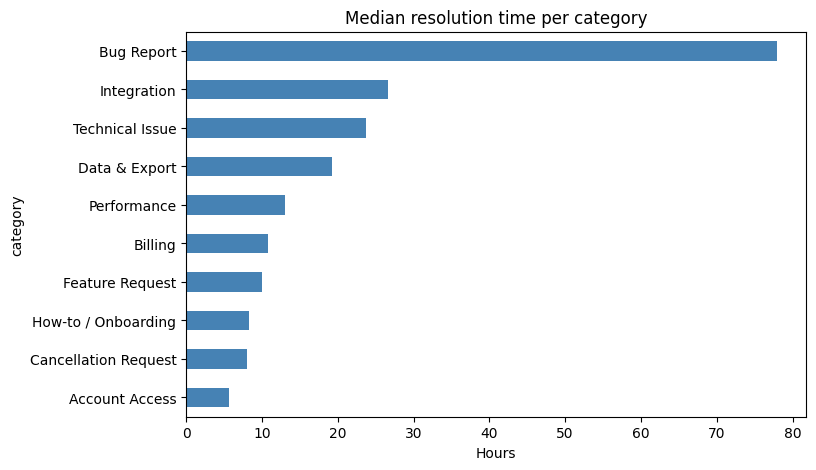

,tickets,median_first_response_min,median_resolution_hrs,p90_resolution_hrs,escalated_pct
category,,,,,
Bug Report,1364,56.0,77.9,251.6,33.1
Integration,1991,34.6,26.6,89.5,0.0
Technical Issue,3041,50.5,23.7,86.1,10.5
Data & Export,772,46.2,19.3,67.2,9.2
Performance,1040,46.2,13.1,49.0,11.3
Billing,2648,71.9,10.8,35.7,0.0
Feature Request,1035,89.2,10.0,39.5,12.6
How-to / Onboarding,2504,88.8,8.3,40.5,12.2
Cancellation Request,913,108.1,8.0,26.7,0.0


In [107]:
time_by_cat = t.groupby('category').agg(
    tickets=('ticket_id', 'count'),
    median_first_response_min=('first_response_time_min', 'median'),
    median_resolution_hrs=('resolution_time_hrs', 'median'),
    p90_resolution_hrs=('resolution_time_hrs', lambda s: s.quantile(0.9)),
    escalated_pct=('escalated', 'mean'),
)
time_by_cat['escalated_pct'] = time_by_cat['escalated_pct'] * 100
time_by_cat = time_by_cat.round(1).sort_values('median_resolution_hrs', ascending=False)

ax = time_by_cat['median_resolution_hrs'].sort_values().plot(
    kind='barh', figsize=(8, 5), color='steelblue')
ax.set_title('Median resolution time per category')
ax.set_xlabel('Hours')
plt.show()

time_by_cat

**What I see:** Bug Reports take the longest to resolve (median 77.9 hours ≈ 3.2 days, and 1 in 10 takes over 10 days). A third of them (33.1%) are escalated, because they depend on a fix from Engineering. Performance (13.1 h) and Account Access (5.6 h) are resolved quickly, yet they had some of the highest shares of unhappy customers in 3.2, so long resolution times are not what makes those customers unhappy.

**Why it matters:** Cancellation Requests wait the longest for a first reply (median 108 minutes, about 1.8 hours). That is a missed chance to keep customers who are about to leave.

### 3.4 Which categories are linked to churn?

For each ticket I check if the customer churned within 90 days after it (`churned_within_90d`).

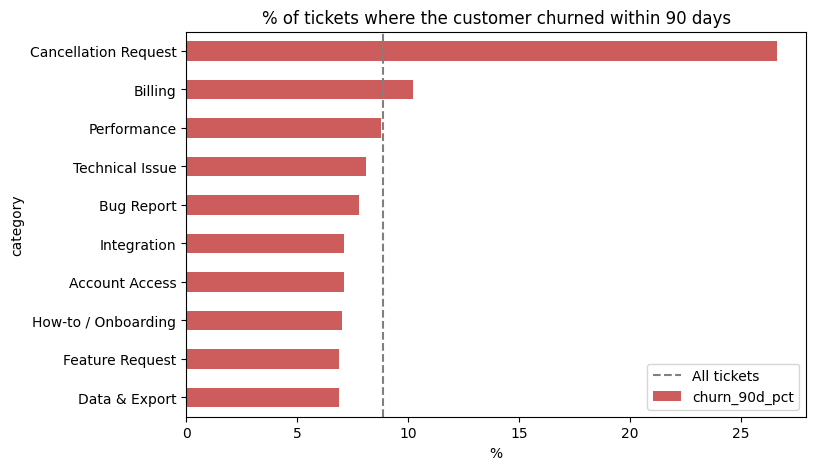

,tickets,churn_90d_tickets,churn_90d_pct,share_of_all_churn_pct
category,,,,
Cancellation Request,913,243,26.6,15.7
Billing,2648,269,10.2,17.4
Performance,1040,91,8.8,5.9
Technical Issue,3041,245,8.1,15.9
Bug Report,1364,106,7.8,6.9
Account Access,2073,147,7.1,9.5
Integration,1991,142,7.1,9.2
How-to / Onboarding,2504,176,7.0,11.4
Feature Request,1035,71,6.9,4.6


In [108]:
churn_tickets = t.groupby('category').agg(
    tickets=('ticket_id', 'count'),
    churn_90d_tickets=('churned_within_90d', 'sum'),
    churn_90d_pct=('churned_within_90d', 'mean'),
)
churn_tickets['churn_90d_pct'] = churn_tickets['churn_90d_pct'] * 100
churn_tickets['share_of_all_churn_pct'] = (churn_tickets['churn_90d_tickets']
                                           / churn_tickets['churn_90d_tickets'].sum() * 100)
churn_tickets = churn_tickets.round(1).sort_values('churn_90d_pct', ascending=False)

ax = churn_tickets['churn_90d_pct'].sort_values().plot(kind='barh', figsize=(8, 5), color='indianred')
ax.axvline(t['churned_within_90d'].mean() * 100, ls='--', c='grey', label='All tickets')
ax.set_title('% of tickets where the customer churned within 90 days')
ax.set_xlabel('%')
ax.legend()
plt.show()

churn_tickets

**What I see:** Apart from Cancellation Requests (26.6%), Billing tickets have the highest churn rate (10.2% of customers churned within 90 days, against 8.9% on average) and make up the largest share of all churn-related tickets (17.4%). The other categories are close together (6.9–8.8%), and Performance, despite its many low CSAT scores, churns at the average rate.

**Why it matters:** A billing ticket is an early warning that a customer may leave, so these tickets deserve fast, careful handling and could trigger a follow-up from Customer Success. The fact that 73.4% of cancellation requests did not churn within 90 days suggests retention efforts may be working.

### 3.5 How fast does the team respond, and how often do we miss the SLA?

In [111]:
print(f"Median first response: {t['first_response_time_min'].median():.1f} minutes")
print(f"Median resolution:     {t['resolution_time_hrs'].median():.1f} hours")
print(f"SLA breached:          {t['sla_breached'].mean() * 100:.1f}% of tickets")

sla_by_priority = t.groupby('priority').agg(
    tickets=('ticket_id', 'count'),
    sla_target_min=('sla_target_min', 'median'),
    median_first_response_min=('first_response_time_min', 'median'),
    sla_breached_pct=('sla_breached', 'mean'),
)
sla_by_priority['sla_breached_pct'] = sla_by_priority['sla_breached_pct'] * 100
sla_by_priority.round(1).sort_values('sla_target_min')

Median first response: 59.5 minutes
Median resolution:     14.0 hours
SLA breached:          11.2% of tickets


,tickets,sla_target_min,median_first_response_min,sla_breached_pct
priority,,,,
Urgent,1432,45.0,24.0,34.2
High,4132,180.0,43.6,14.8
Medium,7659,360.0,68.7,9.6
Low,4158,1440.0,138.8,2.6


**What I see:** The median customer waits **59.5 minutes** for a first reply and **14 hours** for a resolution. Overall, **11.2%** of tickets miss the SLA. The problem is concentrated in **Urgent** tickets: their target is only 45 minutes, and 34.2% of them miss it, against 2.6% of Low tickets.

**Why it matters:** The team is fast on average, but the most important tickets are the ones most often late. Answering Urgent tickets first is the clearest way to reduce SLA breaches.

### 3.6 Does slow or complicated service make customers unhappier?

In [112]:
rows = []
for factor in ['sla_breached', 'escalated', 'reopened']:
    g = t.groupby(factor).agg(
        answers=('csat_score', 'count'),
        avg_csat=('csat_score', 'mean'),
        low_csat_pct=('low_csat', 'mean'),
    )
    g['low_csat_pct'] = g['low_csat_pct'] * 100
    g.index = [f'{factor} = {value}' for value in g.index]
    rows.append(g)

service_csat = pd.concat(rows).round(2)
service_csat

,answers,avg_csat,low_csat_pct
sla_breached = False,6115,4.14,5.46
sla_breached = True,759,3.17,28.85
escalated = False,6216,4.06,7.63
escalated = True,658,3.80,12.01
reopened = False,6322,4.11,6.28
reopened = True,552,3.09,28.26


**What I see:**  When the first reply missed the SLA, 28.9% of customers gave a low score, against 5.5% when it was on time (about 5 times as many). Reopened tickets show the same pattern (28.3% vs 6.3%), while escalation to Tier 2 has a much smaller effect (12.0% vs 7.6%).

**Why it matters:** The two biggest drivers of low satisfaction are a late first reply and a problem that isn’t truly fixed the first time. Protecting the SLA and solving tickets properly the first time will improve CSAT more than avoiding escalations.

In [113]:
# % of unhappy customers per category, when the SLA was met vs breached
problem_vs_service = pd.pivot_table(t, index='category', columns='sla_breached',
                                    values='low_csat', aggfunc='mean').mul(100).round(1)
problem_vs_service.columns = ['SLA met', 'SLA breached']
problem_vs_service['difference'] = problem_vs_service['SLA breached'] - problem_vs_service['SLA met']
problem_vs_service.sort_values('SLA met', ascending=False)

,SLA met,SLA breached,difference
category,,,
Cancellation Request,17.9,49.1,31.2
Account Access,6.3,30.4,24.1
Technical Issue,5.9,27.5,21.6
Billing,5.5,33.3,27.8
Bug Report,5.1,22.0,16.9
Integration,4.6,22.5,17.9
Data & Export,4.5,30.8,26.3
Performance,3.7,37.9,34.2
Feature Request,3.0,5.0,2.0


In [114]:
# Number of CSAT answers behind each % above (small numbers = less reliable)
pd.crosstab(t['category'], t['sla_breached'], values=t['csat_score'], aggfunc='count')

sla_breached,False,True
category,,
Account Access,703,115
Billing,1025,81
Bug Report,488,41
Cancellation Request,351,53
Data & Export,269,26
Feature Request,365,20
How-to / Onboarding,805,70
Integration,717,80
Performance,295,124


**What I see:** In almost every category, customers are far less happy when the SLA is breached. The biggest jump is in **Performance** (3.7% unhappy when on time, 37.9% when late), so Performance's low CSAT in 3.2 comes mostly from slow replies, not from the problem itself. Performance tickets also miss the SLA much more often: 124 of 419 answered tickets (29.6%), almost 3 times the overall rate (11.0%).

Only Cancellation Requests stay unhappy even when the team is on time (17.9%). Speed matters less for How-to questions (1.7% → 10.0%). Feature Request and Data & Export have fewer than 30 late answered tickets, so their "SLA breached" numbers are too uncertain to interpret.

**Why it matters:** Meeting the SLA is the strongest lever support has to improve CSAT, especially for Performance, Billing and Account Access. During incidents, Performance tickets should be answered first.

### 3.7 Can we see the outage and the price increase in the data?

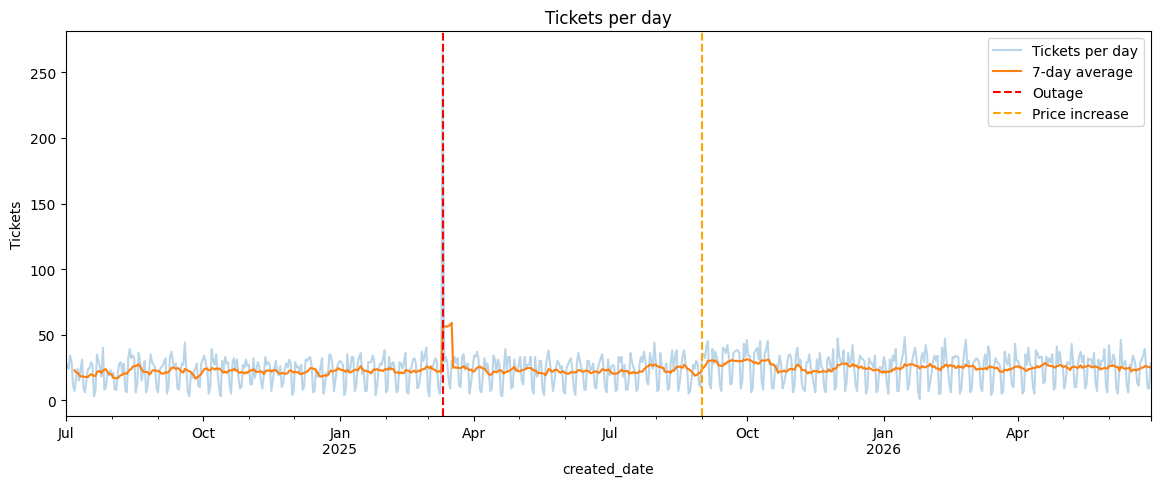

created_date
2025-03-11    268
2026-01-15     48
2025-12-01     47
2026-02-11     47
2025-10-01     46
dtype: int64

In [ ]:
# Tickets per day, with the two business events marked
daily = t.groupby('created_date').size().asfreq('D', fill_value=0)

fig, ax = plt.subplots(figsize=(14, 5))
daily.plot(ax=ax, alpha=0.3, label='Tickets per day')
daily.rolling(7).mean().plot(ax=ax, label='7-day average')
ax.axvline(pd.Timestamp('2025-03-11'), color='red', ls='--', label='Outage')
ax.axvline(pd.Timestamp('2025-09-01'), color='orange', ls='--', label='Price increase')
ax.set_title('Tickets per day')
ax.set_ylabel('Tickets')
ax.legend()
plt.show()

daily.sort_values(ascending=False).head(5)

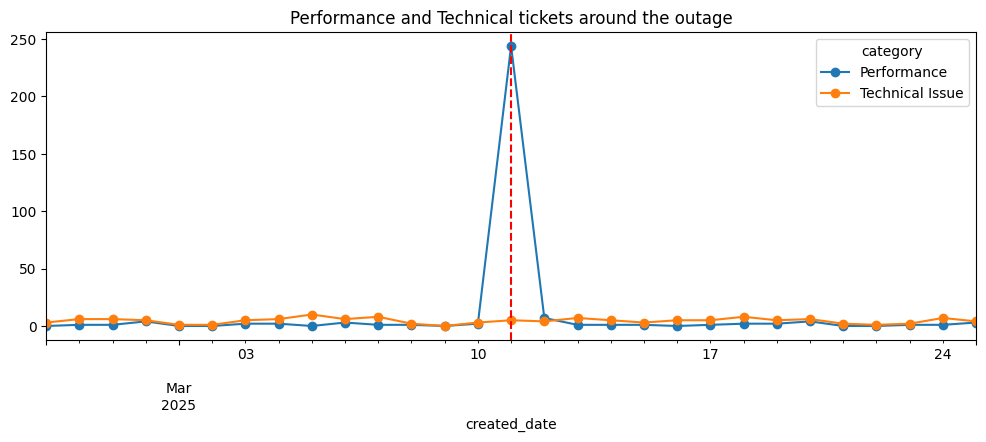

,tickets,sla_breached_pct,low_csat_pct
outage_days,,,
False,788,19.4,9.9
True,252,52.0,25.2


In [118]:
# Zoom in on the days around the outage
window = t[t['created_date'].between('2025-02-25', '2025-03-25')]
outage_daily = pd.crosstab(window['created_date'], window['category'])[['Performance', 'Technical Issue']]

ax = outage_daily.plot(figsize=(12, 4), marker='o', title='Performance and Technical tickets around the outage')
ax.axvline(pd.Timestamp('2025-03-11'), color='red', ls='--')
plt.show()

# Did Performance tickets miss the SLA more during the outage?
outage_days = t['created_date'].between('2025-03-11', '2025-03-13')
perf = t[t['category'] == 'Performance']
outage_effect = perf.groupby(outage_days[perf.index].rename('outage_days')).agg(
    tickets=('ticket_id', 'count'),
    sla_breached_pct=('sla_breached', 'mean'),
    low_csat_pct=('low_csat', 'mean'),
)
outage_effect[['sla_breached_pct', 'low_csat_pct']] *= 100
outage_effect.round(1)

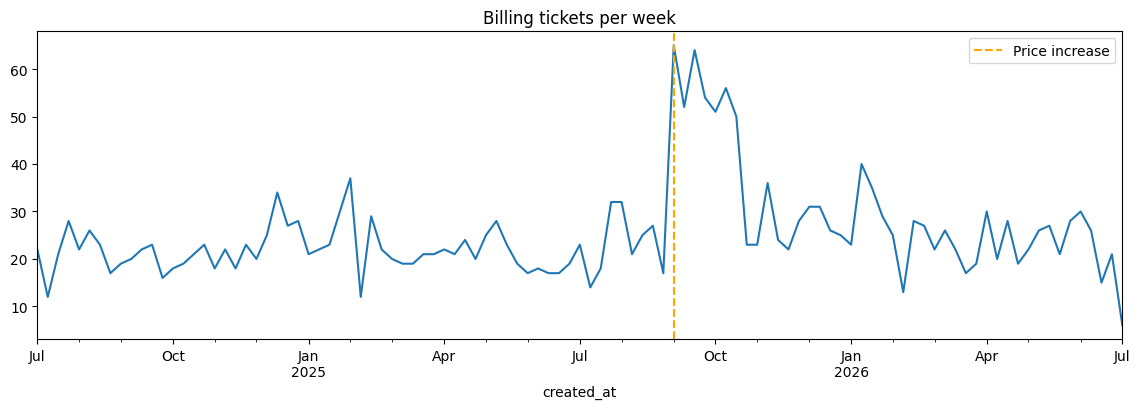

,tickets,price_question_pct,low_csat_pct,churn_90d_pct
period,,,,
1. Before,280,13.9,7.3,8.6
2. After,548,45.4,5.7,13.9


In [117]:
billing = t[t['category'] == 'Billing']

# Billing tickets per week. The last week is incomplete (data ends on a Tuesday), so I drop it.
weekly = billing.set_index('created_at').resample('W').size().iloc[:-1]
ax = weekly.plot(figsize=(14, 4), title='Billing tickets per week')
ax.axvline(pd.Timestamp('2025-09-01'), color='orange', ls='--', label='Price increase')
ax.legend()
plt.show()

# 3 months before vs 3 months after
before = billing['created_date'].between('2025-06-01', '2025-08-31')
after = billing['created_date'].between('2025-09-01', '2025-11-30')
period = pd.Series(np.where(before, '1. Before', np.where(after, '2. After', 'other')),
                   index=billing.index, name='period')

price_effect = billing[period != 'other'].groupby(period).agg(
    tickets=('ticket_id', 'count'),
    price_question_pct=('subcategory', lambda s: (s == 'Price increase question').mean() * 100),
    low_csat_pct=('low_csat', lambda s: s.mean() * 100),
    churn_90d_pct=('churned_within_90d', lambda s: s.mean() * 100),
).round(1)
price_effect

**What I see:** Both events built into the data are clearly visible, so the method works.

**Platform outage (11 March 2025)**
- 11 March 2025 is by far the busiest day in the data: **268 tickets**, about 11 times a normal day (≈24) and 5.6 times the next busiest day (48).
- The spike lasted **one day** and came only from **Performance** tickets (≈243 that day, almost none on a normal day). Technical Issue tickets did not change.
- During the outage days, **52.0%** of Performance tickets missed the SLA (vs 19.4% on normal days), and the share of unhappy customers rose from **9.9% to 25.2%**. This explains most of Performance's low CSAT in section 3.2.
- Even on normal days, Performance misses the SLA more often than average (19.4% vs 11.0%), which needs attention on its own.
- *Note:* the week-long bump in the 7-day average is an effect of the averaging, not a longer incident.

**Price increase (1 September 2025)**
- Billing tickets jumped from about 20 to about 65 per week, stayed high for around **7 weeks**, then returned to normal. A smaller rise in early August suggests customers already reacted when the increase was announced.
- Comparing 3 months before and after: Billing tickets almost doubled (**280 → 548**), and questions about the new price went from **13.9% to 45.4%** of them.
- CSAT stayed good (unhappy customers fell from 7.3% to 5.7%), but churn within 90 days rose from **8.6% to 13.9%**.

**Why it matters**
- Outages flood one category in a single day. Reporting the SLA with and without declared incidents gives a fair view of the team's performance, and Performance tickets should be prioritised during incidents.
- Support handled the price questions well, but customers still left. **CSAT alone hides this risk.** Billing tickets after a price change should trigger a follow-up from Customer Success, for example a retention offer.

**Limitations**
- The before/after comparison doesn't prove the price increase caused the extra churn, because other factors (such as the time of year) could play a role. Comparing with non-Billing tickets in the same months would make it stronger.
- The last week in the weekly chart is incomplete (the data ends on Tuesday 30 June 2026), so it was removed.

### 3.8 Which customers churn? (customer level)

Up to now I looked at tickets. Here I look at customers: for each category, do customers who opened that kind of ticket churn more than customers who didn't?
`lift` = churn with ÷ churn without (above 1 = higher risk).

In [119]:
had_cat = pd.crosstab(t['customer_id'], t['category']) > 0
had_cat = had_cat.join(customers.set_index('customer_id')['churned'])

print(f"Churn among customers with tickets: {had_cat['churned'].mean() * 100:.1f}%")

rows = []
for category in t['category'].unique():
    with_it = had_cat[had_cat[category]]
    without_it = had_cat[~had_cat[category]]
    rows.append({
        'category': category,
        'customers_with_it': len(with_it),
        'churn_with_pct': with_it['churned'].mean() * 100,
        'churn_without_pct': without_it['churned'].mean() * 100,
    })

churn_by_cat = pd.DataFrame(rows).set_index('category')
churn_by_cat['lift'] = churn_by_cat['churn_with_pct'] / churn_by_cat['churn_without_pct']
churn_by_cat = churn_by_cat.round(2).sort_values('lift', ascending=False)
churn_by_cat

Churn among customers with tickets: 27.6%


,customers_with_it,churn_with_pct,churn_without_pct,lift
category,,,,
Cancellation Request,631,50.71,21.27,2.38
Billing,1472,26.49,28.77,0.92
Performance,842,23.16,29.43,0.79
Technical Issue,1579,24.19,31.65,0.76
Feature Request,759,21.61,29.73,0.73
Account Access,1195,21.76,31.68,0.69
Bug Report,960,20.94,30.89,0.68
Data & Export,606,19.80,29.67,0.67
How-to / Onboarding,1409,21.72,33.11,0.66


In [120]:
# % of tickets followed by churn within 90 days, per category and plan
pd.pivot_table(t, index='category', columns='plan_tier',
               values='churned_within_90d', aggfunc='mean').mul(100).round(1)

plan_tier,Business,Enterprise,Professional,Starter
category,,,,
Account Access,5.0,3.4,7.5,15.5
Billing,6.6,2.7,12.6,17.6
Bug Report,4.6,3.2,8.0,16.1
Cancellation Request,15.3,8.2,30.2,49.3
Data & Export,5.0,3.7,8.6,10.7
Feature Request,5.1,2.2,9.6,10.5
How-to / Onboarding,5.7,3.1,9.6,9.3
Integration,4.8,2.7,11.2,15.6
Performance,6.7,2.1,8.1,15.5


**What I see:** Customers who sent a Cancellation Request churned 2.4 times as often as other customers (50.7% vs 21.3%). For every other category the lift is **below 1**, so customers with those tickets churned *less*. This doesn't mean tickets keep customers: customers who stay longer simply have more time to open all kinds of tickets, while churners leave early. Billing is the closest to 1 (0.92), which fits what I saw in 3.4.

The second table shows that the **plan** matters more than the category: Starter customers churn far more often in every category (9–18%, and 49% after a cancellation request), while Enterprise customers rarely churn (2–4%).

**Why it matters:** simple "had this ticket or not" comparisons can mislead, because they ignore how long each customer was observed. The model in section 4 corrects for this by using tickets *per month*.

## 4. Churn prediction

**Question:** Can we predict which customers will churn from their support history?

I use a **logistic regression**, a simple model that is easy to explain. The steps:

1. Build one row per customer
2. Compare churners with customers who stayed
3. Choose the inputs and split into train and test
4. Train the model
5. Evaluate it
6. See which inputs drive churn risk

To avoid **data leakage**, I only use tickets created *before* the customer churned, and I leave out Cancellation Requests (they almost give away the answer).

**Step 1 – One row per customer**

In [121]:
DATA_START = pd.Timestamp('2024-07-01')
DATA_END = pd.Timestamp('2026-07-01')   # the day after the last day of data

cust = customers[['customer_id', 'plan_tier', 'billing_cycle', 'seats', 'mrr_usd',
                  'signup_date', 'churned', 'churn_date']].copy()

# 1. Keep only tickets from BEFORE the customer churned, and leave out cancellation requests
churn_day = t['customer_id'].map(cust.set_index('customer_id')['churn_date'])
before_churn = churn_day.isna() | (t['created_at'] < churn_day)
history = t[before_churn & (t['category'] != 'Cancellation Request')]

# 2. How many months we could watch each customer
start = cust['signup_date'].clip(lower=DATA_START)
end = cust['churn_date'].fillna(DATA_END).clip(upper=DATA_END)
cust['observed_months'] = ((end - start).dt.days / 30.44).clip(lower=1)

# 3. Support history per customer
support = history.groupby('customer_id').agg(
    n_tickets=('ticket_id', 'count'),
    sla_breached_pct=('sla_breached', 'mean'),
    escalated_pct=('escalated', 'mean'),
    reopened_pct=('reopened', 'mean'),
    csat_answers=('csat_score', 'count'),
    avg_csat=('csat_score', 'mean'),
)
support[['sla_breached_pct', 'escalated_pct', 'reopened_pct']] *= 100

# Share of each ticket type, e.g. share_billing = % of the customer's tickets that were Billing
cat_share = pd.crosstab(history['customer_id'], history['category'], normalize='index') * 100
cat_share.columns = ['share_' + re.sub(r'[^a-z]+', '_', col.lower()).strip('_') for col in cat_share.columns]

# 4. One row per customer
model_df = cust.set_index('customer_id').join(support).join(cat_share)

# 5. Customers without tickets: fill with 0, and flags so the model knows what was missing
model_df['has_tickets'] = model_df['n_tickets'].notna()
model_df['csat_missing'] = model_df['avg_csat'].isna()
fill_zero = ['n_tickets', 'sla_breached_pct', 'escalated_pct', 'reopened_pct', 'csat_answers'] + list(cat_share.columns)
model_df[fill_zero] = model_df[fill_zero].fillna(0)
model_df['avg_csat'] = model_df['avg_csat'].fillna(model_df['avg_csat'].median())

model_df['tickets_per_month'] = model_df['n_tickets'] / model_df['observed_months']
model_df['churned'] = model_df['churned'].astype(int)
model_df = model_df.drop(columns=['signup_date', 'churn_date'])

# 6. Checks
print('Rows (customers):', len(model_df))
print(f"Churn rate: {model_df['churned'].mean() * 100:.1f}%")
print('Missing values left:', model_df.isna().sum().sum())
print('Leakage columns besides the target:',
      [col for col in model_df.columns if col in LEAKAGE_COLS and col != 'churned'])
model_df.head()

Rows (customers): 3200
Churn rate: 26.0%
Missing values left: 0
Leakage columns besides the target: []


,plan_tier,billing_cycle,seats,mrr_usd,churned,observed_months,n_tickets,sla_breached_pct,escalated_pct,reopened_pct,...,share_bug_report,share_data_export,share_feature_request,share_how_to_onboarding,share_integration,share_performance,share_technical_issue,has_tickets,csat_missing,tickets_per_month
customer_id,,,,,,,,,,,,,,,,,,,,,
CUST-10001,Business,Monthly,74,3626.00,0,7.818660,1.0,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,True,True,0.127899
CUST-10002,Business,Monthly,123,6027.00,0,23.981603,9.0,11.111111,11.111111,0.000000,...,11.111111,0.000000,11.111111,0.000000,22.222222,0.0,11.111111,True,False,0.375288
CUST-10003,Enterprise,Annual,1850,85975.87,1,14.126150,12.0,8.333333,16.666667,16.666667,...,0.000000,16.666667,0.000000,8.333333,8.333333,0.0,25.000000,True,False,0.849488
CUST-10004,Professional,Monthly,8,232.00,1,1.000000,2.0,50.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,100.000000,0.000000,0.0,0.000000,True,False,2.000000
CUST-10005,Starter,Monthly,1,12.00,0,23.981603,4.0,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,75.000000,True,False,0.166795


**Step 2 – How do churners differ?**

In [122]:
# Average of every column for customers who stayed (0) and who churned (1)
model_df.groupby('churned').mean(numeric_only=True).T.round(2)

churned,0,1
seats,96.92,52.99
mrr_usd,4670.73,2420.97
observed_months,19.65,11.21
n_tickets,5.59,3.88
sla_breached_pct,10.21,14.03
escalated_pct,9.79,9.46
reopened_pct,6.71,8.39
csat_answers,2.19,1.55
avg_csat,4.20,4.04
share_account_access,10.57,10.34


**What I see:** Customers who churned are smaller (about half the seats and MRR), contact support more often (0.41 vs 0.28 tickets per month), and had worse service: more SLA breaches (14.0% vs 10.2% of their tickets) and more reopened tickets (8.4% vs 6.7%). A larger share of their tickets were about Billing (18.8% vs 14.0%). Escalation shows no difference.
*Note:* `observed_months`, `n_tickets` and `csat_answers` depend on how long a customer was observed, and churners were observed for less time because they left. These three columns are therefore not used as model inputs.

**Step 3 – Inputs and train/test split**

In [123]:
# Columns NOT used as inputs:
# - churned: the answer the model must predict
# - observed_months, n_tickets, csat_answers: they depend on how long we watched the customer,
#   and churned customers were watched for a shorter time because they left
target = 'churned'
not_inputs = [target, 'observed_months', 'n_tickets', 'csat_answers']

X = model_df.drop(columns=not_inputs)
y = model_df[target]

# Text columns (plan_tier, billing_cycle) become 0/1 columns, e.g. plan_tier_Starter
X = pd.get_dummies(X, columns=['plan_tier', 'billing_cycle'], drop_first=True, dtype=int)
X[['has_tickets', 'csat_missing']] = X[['has_tickets', 'csat_missing']].astype(int)

# 80% to train the model, 20% to test it on customers it has never seen
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print('Inputs:', X.shape[1])
print('Train customers:', len(X_train), f'| churn {y_train.mean() * 100:.1f}%')
print('Test customers: ', len(X_test), f'| churn {y_test.mean() * 100:.1f}%')
list(X.columns)

Inputs: 22
Train customers: 2560 | churn 26.0%
Test customers:  640 | churn 26.1%


['seats',
 'mrr_usd',
 'sla_breached_pct',
 'escalated_pct',
 'reopened_pct',
 'avg_csat',
 'share_account_access',
 'share_billing',
 'share_bug_report',
 'share_data_export',
 'share_feature_request',
 'share_how_to_onboarding',
 'share_integration',
 'share_performance',
 'share_technical_issue',
 'has_tickets',
 'csat_missing',
 'tickets_per_month',
 'plan_tier_Enterprise',
 'plan_tier_Professional',
 'plan_tier_Starter',
 'billing_cycle_Monthly']

**Step 4 – Train the model**

`StandardScaler` puts all inputs on the same scale, and `class_weight='balanced'` makes the model pay more attention to churners, who are the smaller group.

In [124]:
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)                # 0 = will stay, 1 = will churn
y_prob = model.predict_proba(X_test)[:, 1]    # churn probability between 0 and 1

print('Model trained.')
print(f'Test customers predicted to churn: {y_pred.mean() * 100:.1f}%')
print(f'Test customers who really churned: {y_test.mean() * 100:.1f}%')

Model trained.
Test customers predicted to churn: 39.4%
Test customers who really churned: 26.1%


**Step 5 – Evaluate on test customers**

Accuracy if we always say 'won't churn': 73.9%
Model accuracy:                          66.7%
ROC-AUC:                                 0.699

              precision    recall  f1-score   support

      Stayed      0.835     0.685     0.753       473
     Churned      0.409     0.617     0.492       167

    accuracy                          0.667       640
   macro avg      0.622     0.651     0.622       640
weighted avg      0.724     0.667     0.685       640



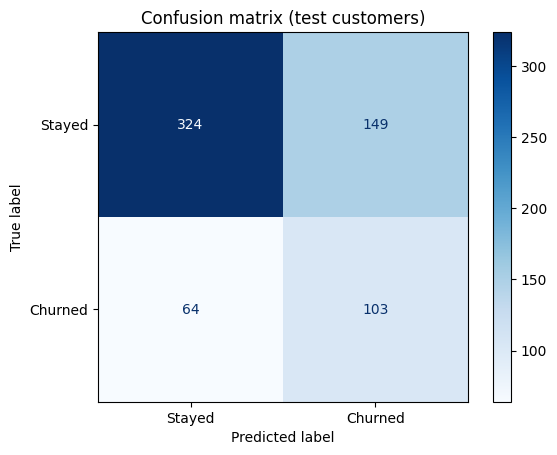

In [125]:
print(f"Accuracy if we always say 'won't churn': {(1 - y_test.mean()) * 100:.1f}%")
print(f"Model accuracy:                          {(y_pred == y_test).mean() * 100:.1f}%")
print(f"ROC-AUC:                                 {roc_auc_score(y_test, y_prob):.3f}")
print()
print(classification_report(y_test, y_pred, target_names=['Stayed', 'Churned'], digits=3))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['Stayed', 'Churned'], cmap='Blues')
plt.title('Confusion matrix (test customers)')
plt.show()

**What I see (640 test customers):** The model catches 103 of the 167 customers who churned (recall 61.7%). Of the 252 customers it flags, 103 really churned (precision 40.9%), about 1.6 times better than picking customers at random (26.1%). Accuracy (66.7%) is lower than always predicting "won't churn" (73.9%), but that lazy approach finds no churners at all, so recall is the better measure here. ROC-AUC is 0.70: a moderate model, clearly better than guessing. That is reasonable given that most churners leave without giving a reason and the model only sees support and account data.

**Why it matters:** By contacting the 40% of customers the model flags, Customer Success would reach about 6 in 10 of the customers who are about to leave.

**Step 6 – What drives churn risk?**

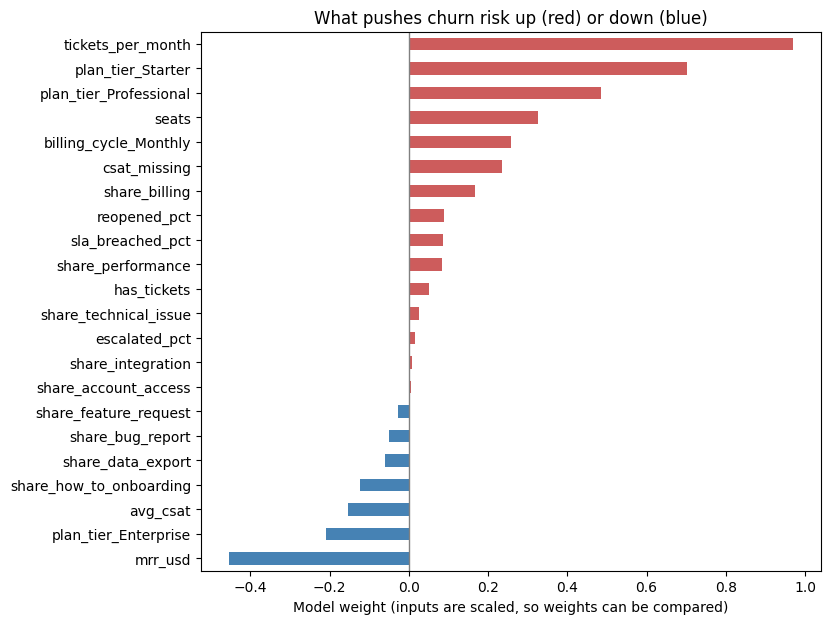

tickets_per_month          0.97
plan_tier_Starter          0.70
plan_tier_Professional     0.48
seats                      0.33
billing_cycle_Monthly      0.26
csat_missing               0.24
share_billing              0.17
reopened_pct               0.09
sla_breached_pct           0.09
share_performance          0.08
has_tickets                0.05
share_technical_issue      0.03
escalated_pct              0.01
share_integration          0.01
share_account_access       0.01
share_feature_request     -0.03
share_bug_report          -0.05
share_data_export         -0.06
share_how_to_onboarding   -0.12
avg_csat                  -0.15
plan_tier_Enterprise      -0.21
mrr_usd                   -0.45
dtype: float64

In [126]:
# Model weights: red pushes churn risk up, blue pushes it down
weights = pd.Series(model.named_steps['logisticregression'].coef_[0], index=X.columns).sort_values()

ax = weights.plot(kind='barh', figsize=(8, 7), color=np.where(weights > 0, 'indianred', 'steelblue'))
ax.axvline(0, color='grey', lw=1)
ax.set_title('What pushes churn risk up (red) or down (blue)')
ax.set_xlabel('Model weight (inputs are scaled, so weights can be compared)')
plt.show()

weights.sort_values(ascending=False).round(2)

**What I see:** The strongest signal is how often a customer contacts support (tickets per month): customers who need help often are struggling. Account type matters next: Starter and Professional plans and monthly billing raise the risk, while higher MRR and Enterprise plans lower it. Among support signals, a high share of Billing tickets raises the risk and a higher CSAT lowers it. Customers who never answer the CSAT survey also churn more, which may be a sign of disengagement. SLA breaches and reopened tickets point in the expected direction but have a small effect once plan and activity are known.

*Note:* seats and MRR are closely related, so their weights should be read together: larger, higher-paying customers churn less.

**Why it matters:** Support can use this as an early warning list: frequent contacts, Billing tickets and silence on surveys, especially from Starter and monthly customers, should trigger a check-in from Customer Success.

## 5. Questions and answers

These are the questions I asked at the start of the project, and the answers I found.

**1. Support performance: How fast does the team respond and resolve tickets? How often do we miss the SLA?**
The median first reply takes **59.5 minutes** and the median resolution **14 hours**. **11.2%** of tickets miss the SLA. Urgent tickets are the weak spot: 34.2% miss their 45-minute target, against 2.6% of Low tickets. Bug Reports are the slowest to resolve (median 3.2 days), because a third of them need Engineering. *(Sections 3.3 and 3.5)*

**2. Customer satisfaction: What leads to high or low CSAT?**
The two biggest drivers are a **late first reply** and a ticket that has to be **reopened**. When the SLA is missed, 28.9% of customers are unhappy (vs 5.5% when on time). For reopened tickets it is 28.3% (vs 6.3%). Escalation matters much less (12.0% vs 7.6%). After Cancellation Requests, Performance has the most unhappy customers (13.8%), mainly because of late replies. How-to / Onboarding is the happiest category (2.4%). *(Sections 3.2 and 3.6)*

**3. Customer emotion: What is the tone of the customer messages?**
Not answered yet. The tone is only in the free text of `customer_message`, so it needs NLP (text analysis). This is the next step of the project.

**4. Churn: Which customers cancel, and can we predict it from their support history?**
**26%** of customers churned, most of them without giving a reason (513 of 833). Smaller customers on Starter or Professional plans with monthly billing churn the most, and Enterprise customers rarely do. Customers who contact support often, have many Billing tickets, or never answer surveys are at higher risk. A simple logistic regression finds **62% of churners** (recall) with a ROC-AUC of **0.70**: a moderate model, but clearly better than guessing. *(Sections 3.4, 3.8 and 4)*

**5. Business events: Can we spot the outage and the price increase?**
Yes, both. On **11 March 2025** there were 268 tickets in one day (about 11 times a normal day), almost all about Performance, and half of them missed the SLA. After the **price increase on 1 September 2025**, Billing tickets almost doubled (280 → 548 in 3 months) and churn within 90 days rose from 8.6% to 13.9%, even though CSAT stayed good. *(Section 3.7)*

### Recommendations

- Answer **Urgent** and **Performance** tickets first, especially during incidents.
- Fix problems properly the first time, so tickets don't need to be reopened.
- Treat **Billing** tickets, especially after a price change, as an early churn warning and ask Customer Success to follow up.
- Reply faster to **Cancellation Requests**, which currently wait the longest for a first reply (about 1.8 hours).
- Use the churn model to build a check-in list for Customer Success.

### Limitations

- The data is synthetic, so patterns are cleaner than in a real company.
- Only 39.5% of tickets have a CSAT score.
- The before/after comparisons show a link, not proof of cause.

### Next steps

- Use NLP on `customer_message` to find each customer's emotion (question 3).
- Try other models (for example a random forest) and compare them with the logistic regression.